In [1]:
pip install pandas numpy matplotlib seaborn requests beautifulsoup4

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# Flipkart Product Data Analysis Using Python
## 1. Project Objective
The objective of this project is to collect product information from an authorized data source related to Flipkart, clean and analyze the data using Python, and identify useful business insights through data visualization.
## 2. Website Selection
Website: Flipkart
Website URL: https://www.flipkart.com/
## 3. Tools and Technologies
* Python
* Jupyter Notebook
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Requests
* BeautifulSoup
## 4. Project Workflow
Data Collection → Data Understanding → Data Cleaning → Exploratory Data Analysis → Data Visualization → Business Insights and Recommendations

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from bs4 import BeautifulSoup

In [4]:
print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import pandas as pd

df = pd.read_csv("../Dataset/flipkart_com-ecommerce_sample.csv")

df.head()

,uniq_id,crawl_timestamp,product_url,product_name,product_category_tree,pid,retail_price,discounted_price,image,is_FK_Advantage_product,description,product_rating,overall_rating,brand,product_specifications
0,c2d766ca982eca8304150849735ffef9,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2FF9KEDEFGF,999.0,379.0,"[""http://img5a.flixcart.com/image/short/u/4/a/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
1,7f7036a6d550aaa89d34c77bd39a5e48,2016-03-25 22:59:23 +0000,http://www.flipkart.com/fabhomedecor-fabric-do...,FabHomeDecor Fabric Double Sofa Bed,"[""Furniture >> Living Room Furniture >> Sofa B...",SBEEH3QGU7MFYJFY,32157.0,22646.0,"[""http://img6a.flixcart.com/image/sofa-bed/j/f...",False,FabHomeDecor Fabric Double Sofa Bed (Finish Co...,No rating available,No rating available,FabHomeDecor,"{""product_specification""=>[{""key""=>""Installati..."
2,f449ec65dcbc041b6ae5e6a32717d01b,2016-03-25 22:59:23 +0000,http://www.flipkart.com/aw-bellies/p/itmeh4grg...,AW Bellies,"[""Footwear >> Women's Footwear >> Ballerinas >...",SHOEH4GRSUBJGZXE,999.0,499.0,"[""http://img5a.flixcart.com/image/shoe/7/z/z/r...",False,Key Features of AW Bellies Sandals Wedges Heel...,No rating available,No rating available,AW,"{""product_specification""=>[{""key""=>""Ideal For""..."
3,0973b37acd0c664e3de26e97e5571454,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2F6HUZMQ6SJ,699.0,267.0,"[""http://img5a.flixcart.com/image/short/6/2/h/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
4,bc940ea42ee6bef5ac7cea3fb5cfbee7,2016-03-25 22:59:23 +0000,http://www.flipkart.com/sicons-all-purpose-arn...,Sicons All Purpose Arnica Dog Shampoo,"[""Pet Supplies >> Grooming >> Skin & Coat Care...",PSOEH3ZYDMSYARJ5,220.0,210.0,"[""http://img5a.flixcart.com/image/pet-shampoo/...",False,Specifications of Sicons All Purpose Arnica Do...,No rating available,No rating available,Sicons,"{""product_specification""=>[{""key""=>""Pet Type"",..."


In [6]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (20000, 15)

Column Names:
['uniq_id', 'crawl_timestamp', 'product_url', 'product_name', 'product_category_tree', 'pid', 'retail_price', 'discounted_price', 'image', 'is_FK_Advantage_product', 'description', 'product_rating', 'overall_rating', 'brand', 'product_specifications']


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   uniq_id                  20000 non-null  str    
 1   crawl_timestamp          20000 non-null  str    
 2   product_url              20000 non-null  str    
 3   product_name             20000 non-null  str    
 4   product_category_tree    20000 non-null  str    
 5   pid                      20000 non-null  str    
 6   retail_price             19922 non-null  float64
 7   discounted_price         19922 non-null  float64
 8   image                    19997 non-null  str    
 9   is_FK_Advantage_product  20000 non-null  bool   
 10  description              19998 non-null  str    
 11  product_rating           20000 non-null  str    
 12  overall_rating           20000 non-null  str    
 13  brand                    14136 non-null  str    
 14  product_specifications   19986 no

In [8]:
df.isnull().sum()

uniq_id                       0
crawl_timestamp               0
product_url                   0
product_name                  0
product_category_tree         0
pid                           0
retail_price                 78
discounted_price             78
image                         3
is_FK_Advantage_product       0
description                   2
product_rating                0
overall_rating                0
brand                      5864
product_specifications       14
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df.dtypes

uniq_id                        str
crawl_timestamp                str
product_url                    str
product_name                   str
product_category_tree          str
pid                            str
retail_price               float64
discounted_price           float64
image                          str
is_FK_Advantage_product       bool
description                    str
product_rating                 str
overall_rating                 str
brand                          str
product_specifications         str
dtype: object

In [11]:
df.describe()

,retail_price,discounted_price
count,19922.000000,19922.000000
mean,2979.206104,1973.401767
std,9009.639341,7333.586040
min,35.000000,35.000000
25%,666.000000,350.000000
50%,1040.000000,550.000000
75%,1999.000000,999.000000
max,571230.000000,571230.000000


In [12]:
df.head(10)

,uniq_id,crawl_timestamp,product_url,product_name,product_category_tree,pid,retail_price,discounted_price,image,is_FK_Advantage_product,description,product_rating,overall_rating,brand,product_specifications
0,c2d766ca982eca8304150849735ffef9,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2FF9KEDEFGF,999.0,379.0,"[""http://img5a.flixcart.com/image/short/u/4/a/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
1,7f7036a6d550aaa89d34c77bd39a5e48,2016-03-25 22:59:23 +0000,http://www.flipkart.com/fabhomedecor-fabric-do...,FabHomeDecor Fabric Double Sofa Bed,"[""Furniture >> Living Room Furniture >> Sofa B...",SBEEH3QGU7MFYJFY,32157.0,22646.0,"[""http://img6a.flixcart.com/image/sofa-bed/j/f...",False,FabHomeDecor Fabric Double Sofa Bed (Finish Co...,No rating available,No rating available,FabHomeDecor,"{""product_specification""=>[{""key""=>""Installati..."
2,f449ec65dcbc041b6ae5e6a32717d01b,2016-03-25 22:59:23 +0000,http://www.flipkart.com/aw-bellies/p/itmeh4grg...,AW Bellies,"[""Footwear >> Women's Footwear >> Ballerinas >...",SHOEH4GRSUBJGZXE,999.0,499.0,"[""http://img5a.flixcart.com/image/shoe/7/z/z/r...",False,Key Features of AW Bellies Sandals Wedges Heel...,No rating available,No rating available,AW,"{""product_specification""=>[{""key""=>""Ideal For""..."
3,0973b37acd0c664e3de26e97e5571454,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2F6HUZMQ6SJ,699.0,267.0,"[""http://img5a.flixcart.com/image/short/6/2/h/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
4,bc940ea42ee6bef5ac7cea3fb5cfbee7,2016-03-25 22:59:23 +0000,http://www.flipkart.com/sicons-all-purpose-arn...,Sicons All Purpose Arnica Dog Shampoo,"[""Pet Supplies >> Grooming >> Skin & Coat Care...",PSOEH3ZYDMSYARJ5,220.0,210.0,"[""http://img5a.flixcart.com/image/pet-shampoo/...",False,Specifications of Sicons All Purpose Arnica Do...,No rating available,No rating available,Sicons,"{""product_specification""=>[{""key""=>""Pet Type"",..."
5,c2a17313954882c1dba461863e98adf2,2016-03-25 22:59:23 +0000,http://www.flipkart.com/eternal-gandhi-super-s...,Eternal Gandhi Super Series Crystal Paper Weig...,"[""Eternal Gandhi Super Series Crystal Paper We...",PWTEB7H2E4KCYUE3,430.0,430.0,"[""http://img5a.flixcart.com/image/paper-weight...",False,Key Features of Eternal Gandhi Super Series Cr...,No rating available,No rating available,Eternal Gandhi,"{""product_specification""=>[{""key""=>""Model Name..."
6,ce5a6818f7707e2cb61fdcdbba61f5ad,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2FVVKRBAXHB,1199.0,479.0,"[""http://img6a.flixcart.com/image/short/p/j/z/...",False,Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
7,8542703ca9e6ebdf6d742638dfb1f2ca,2016-03-25 22:59:23 +0000,http://www.flipkart.com/fabhomedecor-fabric-do...,FabHomeDecor Fabric Double Sofa Bed,"[""Furniture >> Living Room Furniture >> Sofa B...",SBEEH3QGYGHFUEXN,32157.0,22646.0,"[""http://img6a.flixcart.com/image/sofa-bed/e/x...",False,FabHomeDecor Fabric Double Sofa Bed (Finish Co...,No rating available,No rating available,FabHomeDecor,"{""product_specification""=>[{""key""=>""Installati..."
8,29c8d290caa451f97b1c32df64477a2c,2016-03-25 22:59:23 +0000,http://www.flipkart.com/dilli-bazaaar-bellies-...,"dilli bazaaar Bellies, Corporate Casuals, Casuals","[""Footwear >> Women's Footwear >> Ballerinas >...",SHOEH3DZBFR88SCK,699.0,

In [13]:
df.columns

Index(['uniq_id', 'crawl_timestamp', 'product_url', 'product_name',
       'product_category_tree', 'pid', 'retail_price', 'discounted_price',
       'image', 'is_FK_Advantage_product', 'description', 'product_rating',
       'overall_rating', 'brand', 'product_specifications'],
      dtype='str')

In [14]:
df.columns.tolist()

['uniq_id',
 'crawl_timestamp',
 'product_url',
 'product_name',
 'product_category_tree',
 'pid',
 'retail_price',
 'discounted_price',
 'image',
 'is_FK_Advantage_product',
 'description',
 'product_rating',
 'overall_rating',
 'brand',
 'product_specifications']

In [16]:
df.columns = df.columns.str.strip()
df.columns

Index(['uniq_id', 'crawl_timestamp', 'product_url', 'product_name',
       'product_category_tree', 'pid', 'retail_price', 'discounted_price',
       'image', 'is_FK_Advantage_product', 'description', 'product_rating',
       'overall_rating', 'brand', 'product_specifications'],
      dtype='str')

In [17]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_percentage

uniq_id                     0.000
crawl_timestamp             0.000
product_url                 0.000
product_name                0.000
product_category_tree       0.000
pid                         0.000
retail_price                0.390
discounted_price            0.390
image                       0.015
is_FK_Advantage_product     0.000
description                 0.010
product_rating              0.000
overall_rating              0.000
brand                      29.320
product_specifications      0.070
dtype: float64

In [18]:
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (20000, 15)


In [19]:
df.select_dtypes(include="object").head()

C:\Users\uppus\AppData\Local\Temp\ipykernel_13908\2301917015.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").head()


,uniq_id,crawl_timestamp,product_url,product_name,product_category_tree,pid,image,description,product_rating,overall_rating,brand,product_specifications
0,c2d766ca982eca8304150849735ffef9,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2FF9KEDEFGF,"[""http://img5a.flixcart.com/image/short/u/4/a/...",Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
1,7f7036a6d550aaa89d34c77bd39a5e48,2016-03-25 22:59:23 +0000,http://www.flipkart.com/fabhomedecor-fabric-do...,FabHomeDecor Fabric Double Sofa Bed,"[""Furniture >> Living Room Furniture >> Sofa B...",SBEEH3QGU7MFYJFY,"[""http://img6a.flixcart.com/image/sofa-bed/j/f...",FabHomeDecor Fabric Double Sofa Bed (Finish Co...,No rating available,No rating available,FabHomeDecor,"{""product_specification""=>[{""key""=>""Installati..."
2,f449ec65dcbc041b6ae5e6a32717d01b,2016-03-25 22:59:23 +0000,http://www.flipkart.com/aw-bellies/p/itmeh4grg...,AW Bellies,"[""Footwear >> Women's Footwear >> Ballerinas >...",SHOEH4GRSUBJGZXE,"[""http://img5a.flixcart.com/image/shoe/7/z/z/r...",Key Features of AW Bellies Sandals Wedges Heel...,No rating available,No rating available,AW,"{""product_specification""=>[{""key""=>""Ideal For""..."
3,0973b37acd0c664e3de26e97e5571454,2016-03-25 22:59:23 +0000,http://www.flipkart.com/alisha-solid-women-s-c...,Alisha Solid Women's Cycling Shorts,"[""Clothing >> Women's Clothing >> Lingerie, Sl...",SRTEH2F6HUZMQ6SJ,"[""http://img5a.flixcart.com/image/short/6/2/h/...",Key Features of Alisha Solid Women's Cycling S...,No rating available,No rating available,Alisha,"{""product_specification""=>[{""key""=>""Number of ..."
4,bc940ea42ee6bef5ac7cea3fb5cfbee7,2016-03-25 22:59:23 +0000,http://www.flipkart.com/sicons-all-purpose-arn...,Sicons All Purpose Arnica Dog Shampoo,"[""Pet Supplies >> Grooming >> Skin & Coat Care...",PSOEH3ZYDMSYARJ5,"[""http://img5a.flixcart.com/image/pet-shampoo/...",Specifications of Sicons All Purpose Arnica Do...,No rating available,No rating available,Sicons,"{""product_specification""=>[{""key""=>""Pet Type"",..."


In [20]:
df["product_name"].head(10)

0                  Alisha Solid Women's Cycling Shorts
1                  FabHomeDecor Fabric Double Sofa Bed
2                                           AW Bellies
3                  Alisha Solid Women's Cycling Shorts
4                Sicons All Purpose Arnica Dog Shampoo
5    Eternal Gandhi Super Series Crystal Paper Weig...
6                  Alisha Solid Women's Cycling Shorts
7                  FabHomeDecor Fabric Double Sofa Bed
8    dilli bazaaar Bellies, Corporate Casuals, Casuals
9                  Alisha Solid Women's Cycling Shorts
Name: product_name, dtype: str

In [21]:
df["product_category_tree"].head(10)

0    ["Clothing >> Women's Clothing >> Lingerie, Sl...
1    ["Furniture >> Living Room Furniture >> Sofa B...
2    ["Footwear >> Women's Footwear >> Ballerinas >...
3    ["Clothing >> Women's Clothing >> Lingerie, Sl...
4    ["Pet Supplies >> Grooming >> Skin & Coat Care...
5    ["Eternal Gandhi Super Series Crystal Paper We...
6    ["Clothing >> Women's Clothing >> Lingerie, Sl...
7    ["Furniture >> Living Room Furniture >> Sofa B...
8    ["Footwear >> Women's Footwear >> Ballerinas >...
9    ["Clothing >> Women's Clothing >> Lingerie, Sl...
Name: product_category_tree, dtype: str

In [22]:
df["product_category_tree"].nunique()

6466

In [23]:
df[["product_name", "retail_price", "discounted_price"]].head(10)

,product_name,retail_price,discounted_price
0,Alisha Solid Women's Cycling Shorts,999.0,379.0
1,FabHomeDecor Fabric Double Sofa Bed,32157.0,22646.0
2,AW Bellies,999.0,499.0
3,Alisha Solid Women's Cycling Shorts,699.0,267.0
4,Sicons All Purpose Arnica Dog Shampoo,220.0,210.0
5,Eternal Gandhi Super Series Crystal Paper Weig...,430.0,430.0
6,Alisha Solid Women's Cycling Shorts,1199.0,479.0
7,FabHomeDecor Fabric Double Sofa Bed,32157.0,22646.0
8,"dilli bazaaar Bellies, Corporate Casuals, Casuals",699.0,349.0
9,Alisha Solid Women's Cycling Shorts,1199.0,479.0


In [24]:
df[["retail_price", "discounted_price"]].isnull().sum()

retail_price        78
discounted_price    78
dtype: int64

In [25]:
df[["product_name", "product_rating", "overall_rating"]].head(10)

,product_name,product_rating,overall_rating
0,Alisha Solid Women's Cycling Shorts,No rating available,No rating available
1,FabHomeDecor Fabric Double Sofa Bed,No rating available,No rating available
2,AW Bellies,No rating available,No rating available
3,Alisha Solid Women's Cycling Shorts,No rating available,No rating available
4,Sicons All Purpose Arnica Dog Shampoo,No rating available,No rating available
5,Eternal Gandhi Super Series Crystal Paper Weig...,No rating available,No rating available
6,Alisha Solid Women's Cycling Shorts,No rating available,No rating available
7,FabHomeDecor Fabric Double Sofa Bed,No rating available,No rating available
8,"dilli bazaaar Bellies, Corporate Casuals, Casuals",No rating available,No rating available
9,Alisha Solid Women's Cycling Shorts,No rating available,No rating available


In [26]:
df[["product_rating", "overall_rating"]].isnull().sum()

product_rating    0
overall_rating    0
dtype: int64

In [27]:
df[["product_rating", "overall_rating"]].dtypes

product_rating    str
overall_rating    str
dtype: object

In [28]:
df["brand"].head(10)

0            Alisha
1      FabHomeDecor
2                AW
3            Alisha
4            Sicons
5    Eternal Gandhi
6            Alisha
7      FabHomeDecor
8     dilli bazaaar
9            Alisha
Name: brand, dtype: str

In [29]:
df["brand"].nunique()

3499

In [30]:
df["brand"].isnull().sum()

np.int64(5864)

In [31]:
df.isnull().sum().sort_values(ascending=False)

brand                      5864
discounted_price             78
retail_price                 78
product_specifications       14
image                         3
description                   2
crawl_timestamp               0
pid                           0
product_category_tree         0
product_name                  0
product_url                   0
uniq_id                       0
is_FK_Advantage_product       0
overall_rating                0
product_rating                0
dtype: int64

In [32]:
df["brand"] = df["brand"].fillna("Unknown")

In [33]:
df["brand"].isnull().sum()

np.int64(0)

In [34]:
df["product_name"].isnull().sum()

np.int64(0)

In [35]:
df["product_category_tree"].isnull().sum()

np.int64(0)

In [36]:
df["description"].isnull().sum()

np.int64(2)

In [37]:
df[["retail_price", "discounted_price"]].isnull().sum()


retail_price        78
discounted_price    78
dtype: int64

In [38]:
df = df.dropna(subset=["retail_price", "discounted_price"])

In [39]:
df[["retail_price", "discounted_price"]].isnull().sum()

retail_price        0
discounted_price    0
dtype: int64

In [40]:
print("Rows and Columns:", df.shape)
print("Total Products:", df.shape[0])
print("Total Columns:", df.shape[1])

Rows and Columns: (19922, 15)
Total Products: 19922
Total Columns: 15


In [41]:
df[["retail_price", "discounted_price"]].dtypes

retail_price        float64
discounted_price    float64
dtype: object

In [42]:
df["retail_price"] = pd.to_numeric(df["retail_price"], errors="coerce")
df["discounted_price"] = pd.to_numeric(df["discounted_price"], errors="coerce")

print(df[["retail_price", "discounted_price"]].dtypes)

retail_price        float64
discounted_price    float64
dtype: object


In [43]:
df["discount_amount"] = df["retail_price"] - df["discounted_price"]

df[["product_name", "retail_price", "discounted_price", "discount_amount"]].head(10)

,product_name,retail_price,discounted_price,discount_amount
0,Alisha Solid Women's Cycling Shorts,999.0,379.0,620.0
1,FabHomeDecor Fabric Double Sofa Bed,32157.0,22646.0,9511.0
2,AW Bellies,999.0,499.0,500.0
3,Alisha Solid Women's Cycling Shorts,699.0,267.0,432.0
4,Sicons All Purpose Arnica Dog Shampoo,220.0,210.0,10.0
5,Eternal Gandhi Super Series Crystal Paper Weig...,430.0,430.0,0.0
6,Alisha Solid Women's Cycling Shorts,1199.0,479.0,720.0
7,FabHomeDecor Fabric Double Sofa Bed,32157.0,22646.0,9511.0
8,"dilli bazaaar Bellies, Corporate Casuals, Casuals",699.0,349.0,350.0
9,Alisha Solid Women's Cycling Shorts,1199.0,479.0,720.0


In [44]:
df["discount_percentage"] = (
    (df["retail_price"] - df["discounted_price"])
    / df["retail_price"]
) * 100

df[["product_name", "retail_price", "discounted_price", "discount_percentage"]].head(10)

,product_name,retail_price,discounted_price,discount_percentage
0,Alisha Solid Women's Cycling Shorts,999.0,379.0,62.062062
1,FabHomeDecor Fabric Double Sofa Bed,32157.0,22646.0,29.576764
2,AW Bellies,999.0,499.0,50.050050
3,Alisha Solid Women's Cycling Shorts,699.0,267.0,61.802575
4,Sicons All Purpose Arnica Dog Shampoo,220.0,210.0,4.545455
5,Eternal Gandhi Super Series Crystal Paper Weig...,430.0,430.0,0.000000
6,Alisha Solid Women's Cycling Shorts,1199.0,479.0,60.050042
7,FabHomeDecor Fabric Double Sofa Bed,32157.0,22646.0,29.576764
8,"dilli bazaaar Bellies, Corporate Casuals, Casuals",699.0,349.0,50.071531
9,Alisha Solid Women's Cycling Shorts,1199.0,479.0,60.050042


In [45]:
print("Zero retail prices:", (df["retail_price"] == 0).sum())
print("Zero discounted prices:", (df["discounted_price"] == 0).sum())

Zero retail prices: 0
Zero discounted prices: 0


In [46]:
df.loc[df["retail_price"] <= 0, "discount_percentage"] = np.nan

In [47]:
df[["retail_price", "discounted_price", "discount_percentage"]].head(10)

,retail_price,discounted_price,discount_percentage
0,999.0,379.0,62.062062
1,32157.0,22646.0,29.576764
2,999.0,499.0,50.050050
3,699.0,267.0,61.802575
4,220.0,210.0,4.545455
5,430.0,430.0,0.000000
6,1199.0,479.0,60.050042
7,32157.0,22646.0,29.576764
8,699.0,349.0,50.071531
9,1199.0,479.0,60.050042


In [48]:
df[["retail_price", "discounted_price", "discount_amount", "discount_percentage"]].describe()

,retail_price,discounted_price,discount_amount,discount_percentage
count,19922.000000,19922.000000,19922.000000,19922.000000
mean,2979.206104,1973.401767,1005.804337,40.523885
std,9009.639341,7333.586040,2301.340266,23.546676
min,35.000000,35.000000,0.000000,0.000000
25%,666.000000,350.000000,180.000000,21.058178
50%,1040.000000,550.000000,456.000000,45.000000
75%,1999.000000,999.000000,900.000000,59.971646
max,571230.000000,571230.000000,87675.000000,96.533333


In [49]:
df["product_category_tree"].value_counts().head(10)

product_category_tree
["Jewellery >> Necklaces & Chains >> Necklaces"]                                                       1562
["Jewellery >> Rings"]                                                                                  709
["Automotive >> Accessories & Spare parts >> Car Interior & Exterior >> Car Interior >> Car Mats"]      521
["Jewellery >> Bangles, Bracelets & Armlets >> Bangles"]                                                429
["Tools & Hardware >> Tools >> Gardening Tools >> Plant Containers & Sets >> Plant Container Sets"]     328
["Jewellery >> Bangles, Bracelets & Armlets >> Bracelets"]                                              250
["Mobiles & Accessories >> Tablet Accessories >> Cases & Covers >> TheLostPuppy Cases & Covers"]        229
["Clothing >> Women's Clothing >> Lingerie, Sleep & Swimwear >> Bras >> S4S Bras"]                      197
["Home Furnishing >> Bed Linen >> Blankets, Quilts & Dohars"]                                           190
["Foot

C:\Users\uppus\AppData\Local\Temp\ipykernel_13908\550488585.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


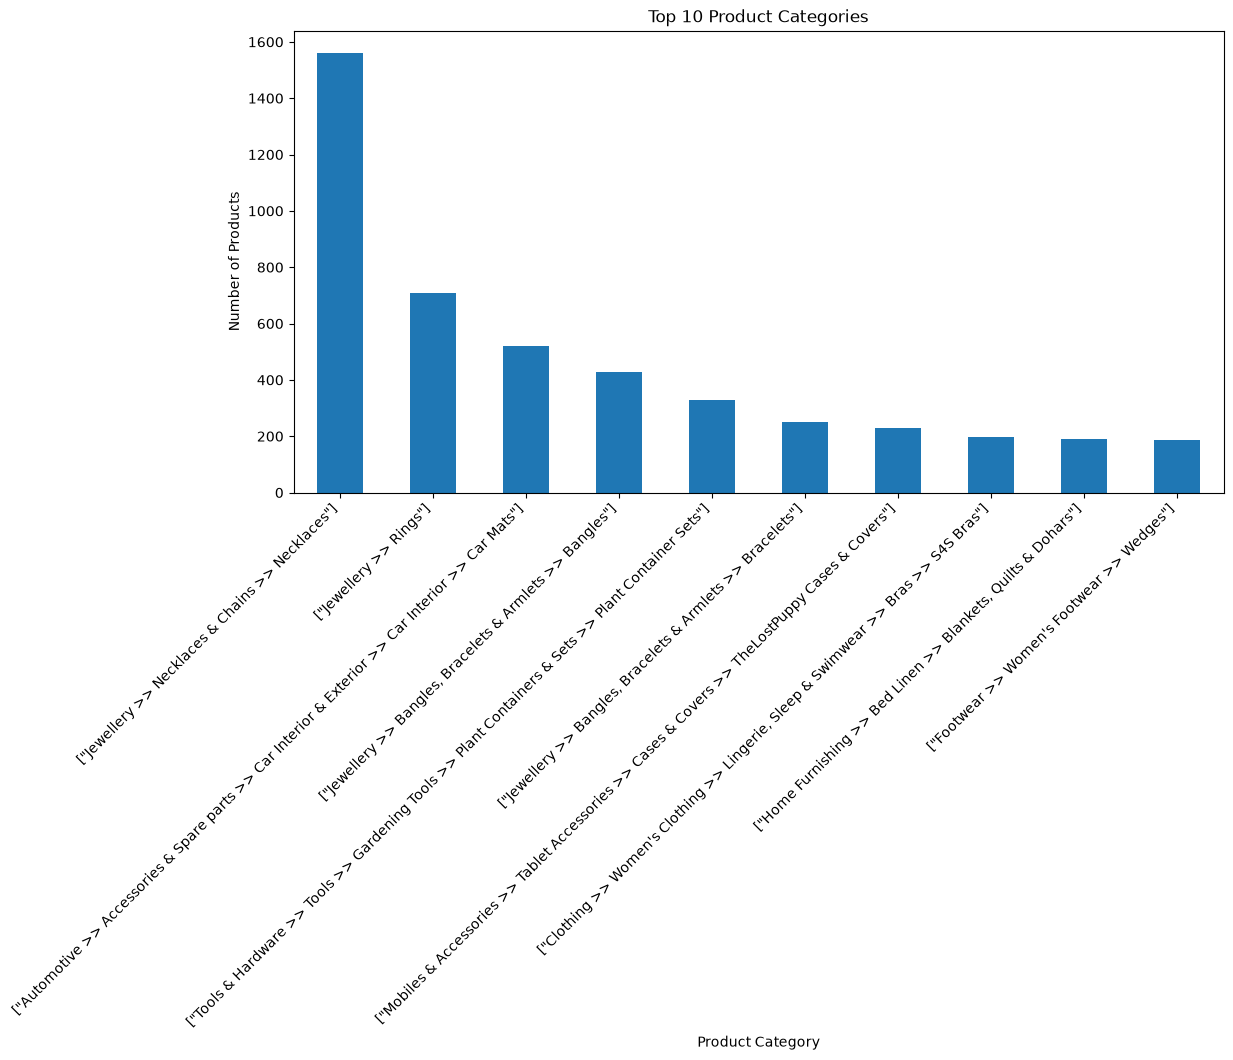

In [50]:
top_categories = df["product_category_tree"].value_counts().head(10)

plt.figure(figsize=(12, 6))
top_categories.plot(kind="bar")

plt.title("Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [51]:
top_brands = df["brand"].value_counts().head(10)

print(top_brands)

brand
Unknown         5851
Allure Auto      468
Regular          308
Voylla           299
Slim             284
TheLostPuppy     229
Karatcraft       211
Black            167
White            155
DailyObjects     144
Name: count, dtype: int64


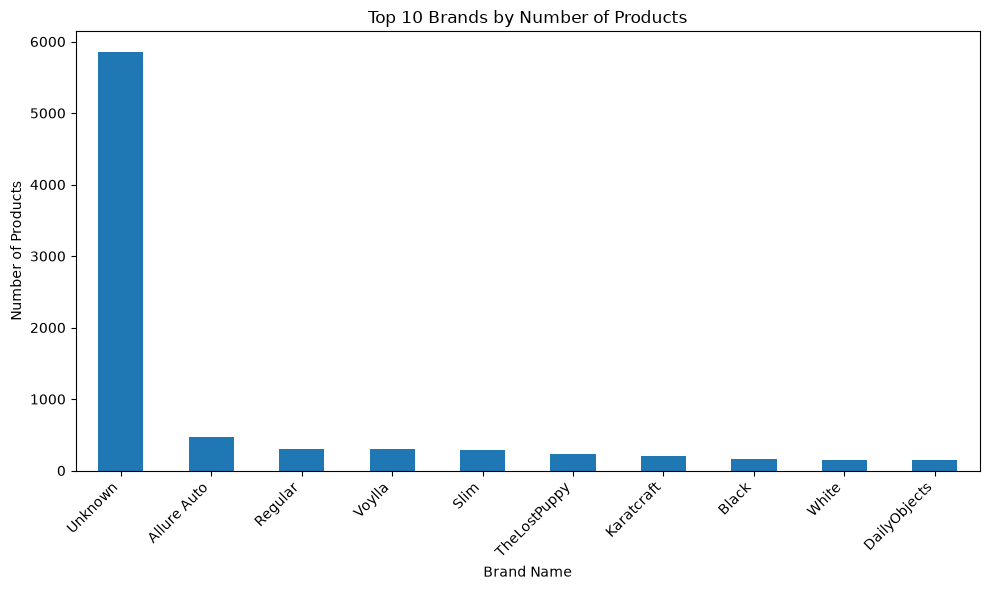

In [52]:
top_brands = df["brand"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_brands.plot(kind="bar")

plt.title("Top 10 Brands by Number of Products")
plt.xlabel("Brand Name")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

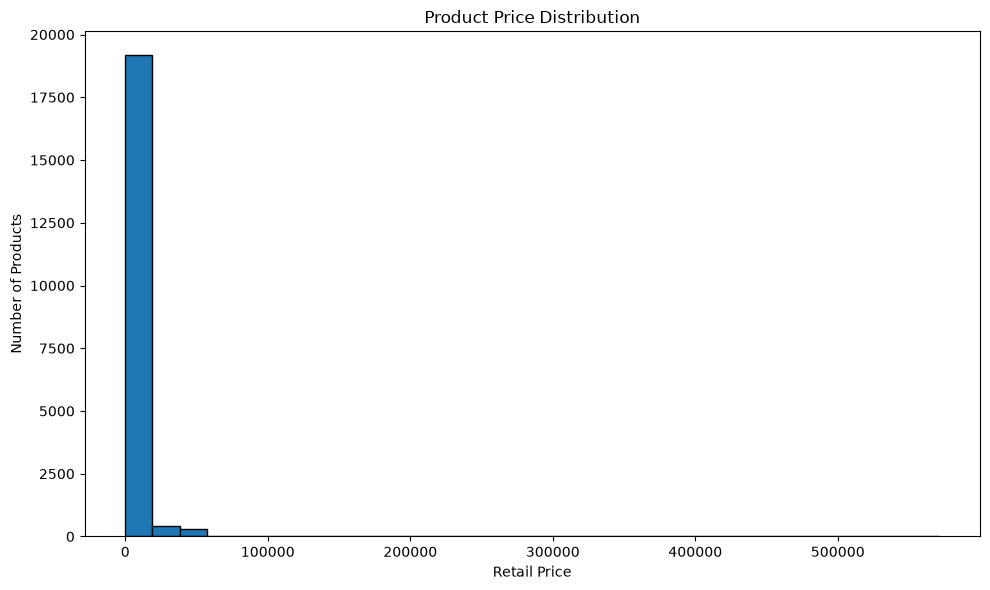

In [53]:
plt.figure(figsize=(10, 6))

plt.hist(df["retail_price"].dropna(), bins=30, edgecolor="black")

plt.title("Product Price Distribution")
plt.xlabel("Retail Price")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

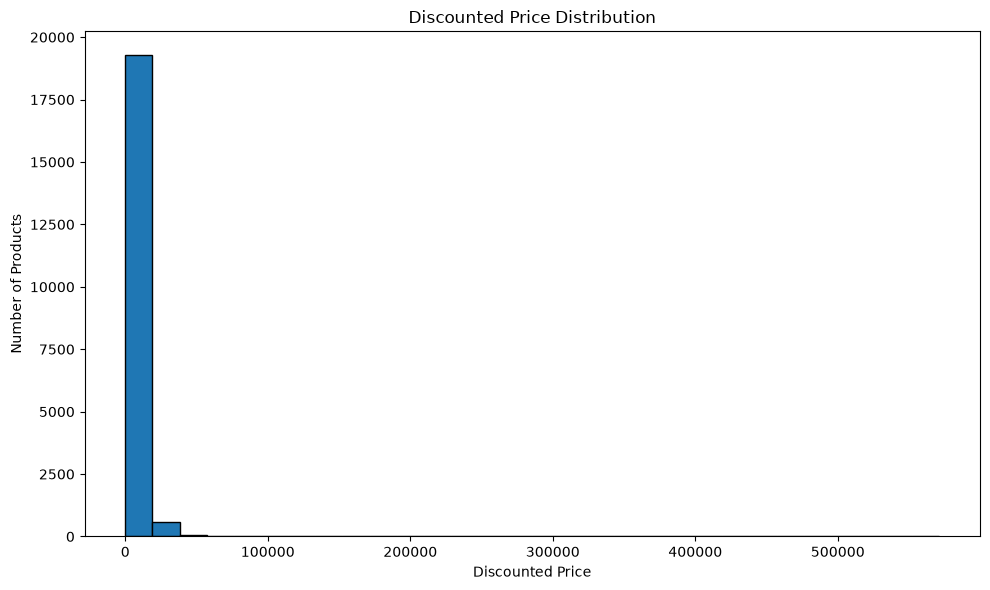

In [54]:
plt.figure(figsize=(10, 6))

plt.hist(df["discounted_price"].dropna(), bins=30, edgecolor="black")

plt.title("Discounted Price Distribution")
plt.xlabel("Discounted Price")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

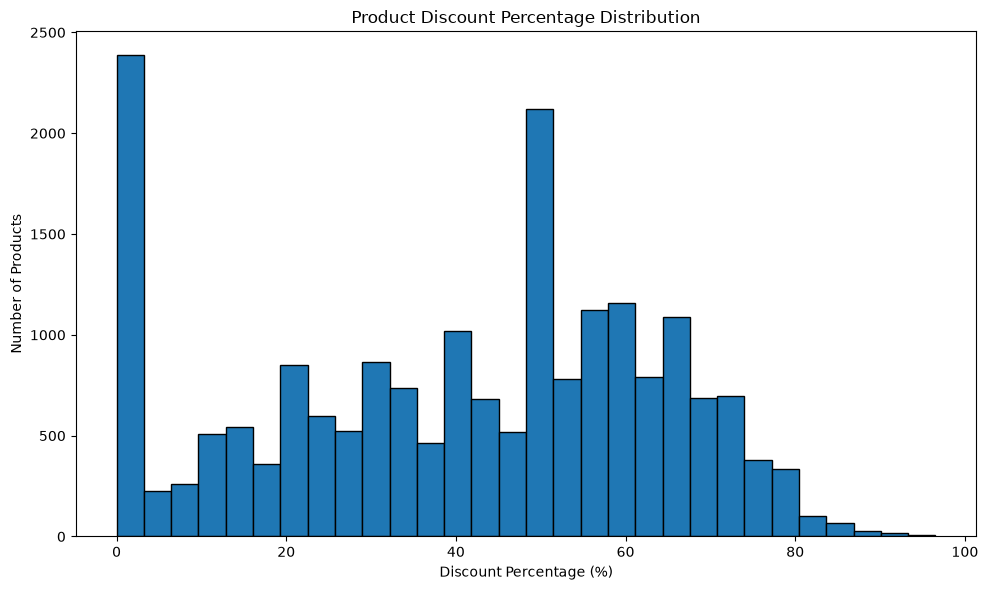

In [55]:
plt.figure(figsize=(10, 6))

plt.hist(df["discount_percentage"].dropna(), bins=30, edgecolor="black")

plt.title("Product Discount Percentage Distribution")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Number of Products")

plt.tight_layout()
plt.show()

In [56]:
top_expensive = df.nlargest(10, "retail_price")

top_expensive[["product_name", "retail_price", "discounted_price"]]

,product_name,retail_price,discounted_price
116,Breitling AB011010/BB08 131S Chronomat 44 Anal...,571230.0,571230.0
11631,Durian Leather 2 Seater Sofa,250500.0,162825.0
11507,Durian Laze/3 Leather 3 Seater Sofa,217500.0,141375.0
11464,Durian Leather 2 Seater Sofa,204600.0,132990.0
134,"Cartier W6701005 Analog Watch - For Boys, Men",201000.0,201000.0
11327,Durian Club/3 Leather 3 Seater Sofa,162000.0,105300.0
7915,"Audeze Lcd2 In Bamboo, High Quality Planar Mag...",116292.0,116292.0
11576,Durian Helena Fabric 3 Seater Sofa,108900.0,70785.0
11702,Durian Helena Fabric 3 Seater Sofa,108900.0,70785.0
11142,Durian Dream/2 Leather 2 Seater Sofa,108000.0,70200.0


In [57]:
top_discounted = df.nlargest(10, "discount_percentage")

top_discounted[
    ["product_name", "retail_price", "discounted_price", "discount_percentage"]
]

,product_name,retail_price,discounted_price,discount_percentage
17205,Rajcrafts Floral Double Quilts & Comforters White,6000.0,208.0,96.533333
7284,FashBlush Forever New Orange Bead & Chain Allo...,3999.0,189.0,95.273818
6566,FashBlush Forever Beautiful White Bead Alloy N...,3499.0,189.0,94.598457
10941,Bling Book Case for iPad 2 / 3,1816.0,99.0,94.548458
6368,FashBlush Forever New BlackBead & LongChain Al...,4999.0,279.0,94.418884
7156,Fashblush Alloy Choker,4499.0,289.0,93.576350
5535,Fash Blush Forever New Gold & White Pearl Chun...,2999.0,199.0,93.364455
6080,FashBlush Forever New BlackBead Alloy Necklace,2999.0,199.0,93.364455
16195,Mydress Mystyle Bulb Led USB Led Light,999.0,75.0,92.492492
5886,Fash Blush Forever New Red & Gold Tribal Threa...,2499.0,198.0,92.076831


In [58]:
brand_price = (
    df[df["brand"] != "Unknown"]
    .groupby("brand")["retail_price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print(brand_price)

brand
Audeze              116292.000000
Durian               73795.483871
Suranas Jewelove     49999.000000
Reet                 49999.000000
Theme Jewels         49178.000000
Caratcents           47422.666667
NITGEN               46328.333333
Ratnam               46324.500000
Jisha                46050.000000
TPH Covers           44880.000000
Name: retail_price, dtype: float64


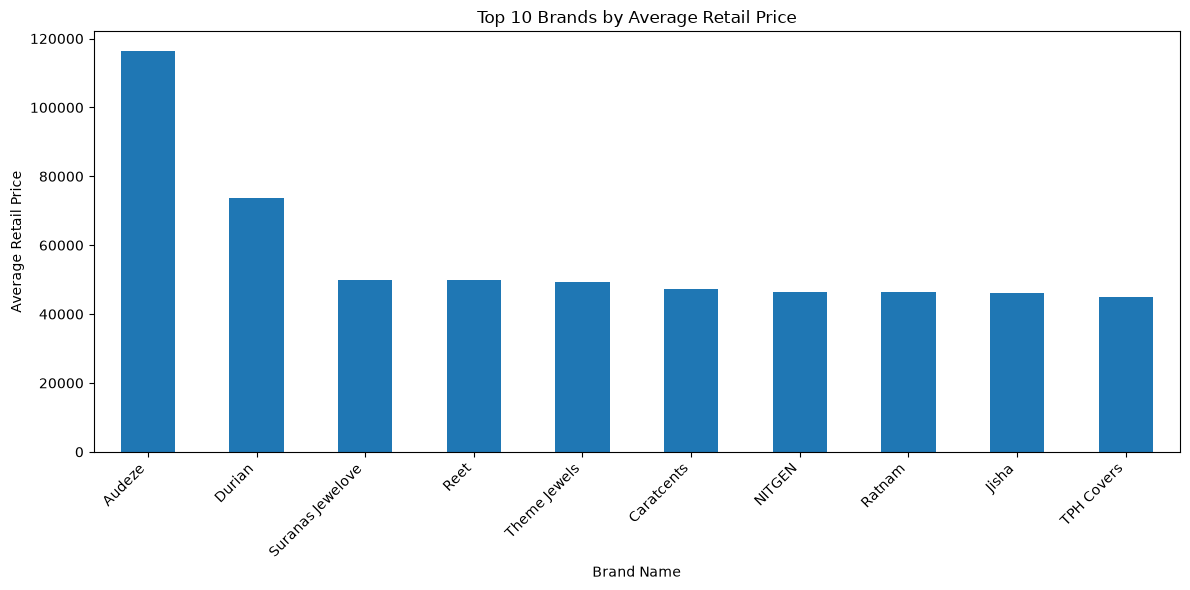

In [59]:
plt.figure(figsize=(12, 6))

brand_price.plot(kind="bar")

plt.title("Top 10 Brands by Average Retail Price")
plt.xlabel("Brand Name")
plt.ylabel("Average Retail Price")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [60]:
brand_discount = (
    df[df["brand"] != "Unknown"]
    .groupby("brand")["discount_percentage"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print(brand_discount)

brand
Rajcrafts          96.533333
Bling              94.548458
Instella           91.719745
Bond Beatz         91.596639
KazamaKraft        90.565618
Mydress Mystyle    90.518987
CUBA               90.045023
SDZ                90.045023
Kaizer Jewelry     89.616918
Fash Blush         89.256770
Name: discount_percentage, dtype: float64


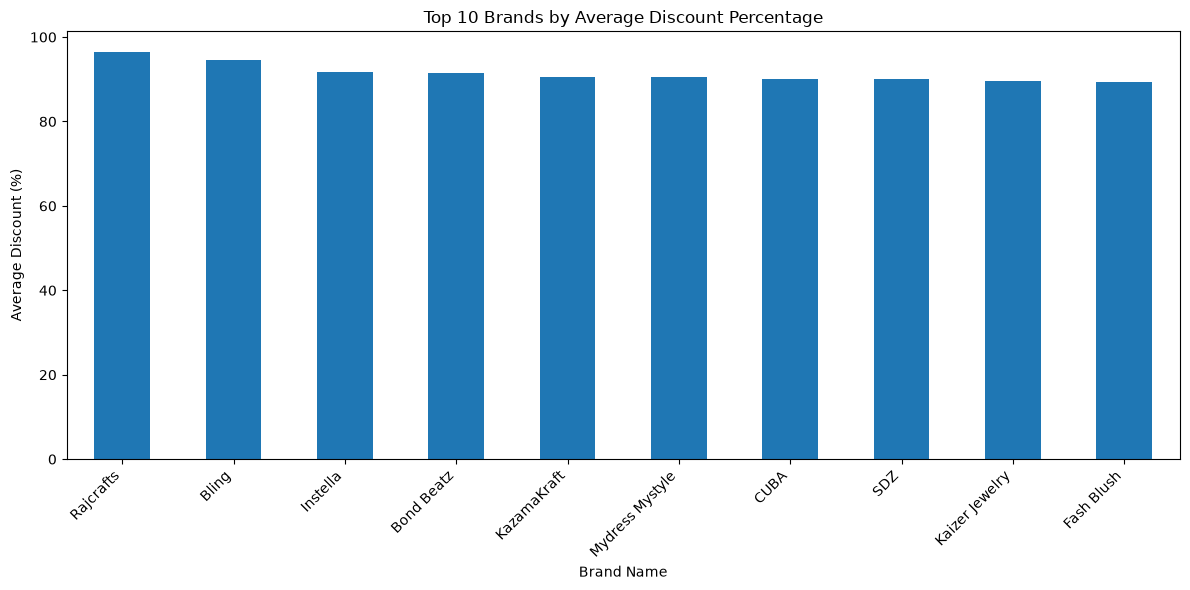

In [61]:
plt.figure(figsize=(12, 6))

brand_discount.plot(kind="bar")

plt.title("Top 10 Brands by Average Discount Percentage")
plt.xlabel("Brand Name")
plt.ylabel("Average Discount (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [62]:
df["product_rating"].value_counts().head(10)

product_rating
No rating available    18083
5                        618
4                        245
1                        169
3                        168
2                         79
4.5                       67
3.7                       51
4.2                       47
3.5                       44
Name: count, dtype: int64

In [63]:
df["product_rating_numeric"] = pd.to_numeric(
    df["product_rating"],
    errors="coerce"
)

df[["product_rating", "product_rating_numeric"]].head(10)

,product_rating,product_rating_numeric
0,No rating available,NaN
1,No rating available,NaN
2,No rating available,NaN
3,No rating available,NaN
4,No rating available,NaN
5,No rating available,NaN
6,No rating available,NaN
7,No rating available,NaN
8,No rating available,NaN
9,No rating available,NaN


In [64]:
df["product_rating_numeric"].mean()

np.float64(3.810331702011963)

In [65]:
df["overall_rating"].value_counts().head(10)

overall_rating
No rating available    18083
5                        618
4                        245
1                        169
3                        168
2                         79
4.5                       67
3.7                       51
4.2                       47
3.5                       44
Name: count, dtype: int64

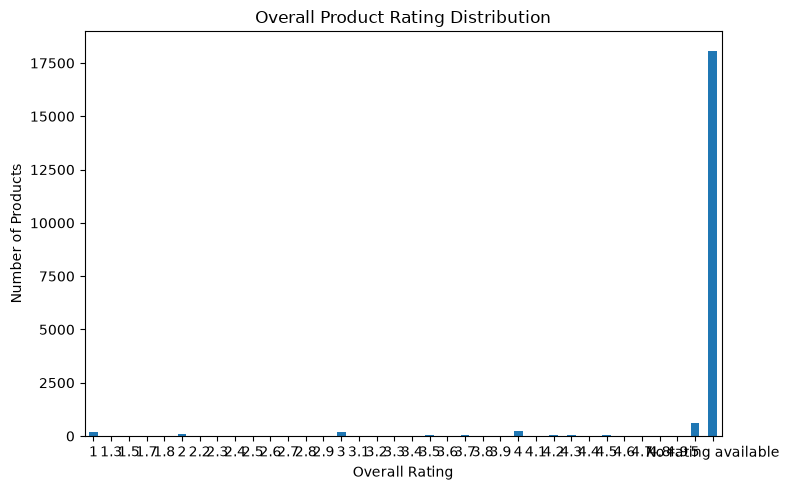

In [66]:
rating_counts = df["overall_rating"].value_counts().sort_index()

plt.figure(figsize=(8, 5))
rating_counts.plot(kind="bar")

plt.title("Overall Product Rating Distribution")
plt.xlabel("Overall Rating")
plt.ylabel("Number of Products")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [67]:
category_price = (
    df.groupby("product_category_tree")["retail_price"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

print(category_price)

product_category_tree
["Watches >> Wrist Watches >> Breitling Wrist Watches"]                                                                                                          571230.000000
["Watches >> Wrist Watches >> Cartier Wrist Watches"]                                                                                                            201000.000000
["Mobiles & Accessories >> Mobile Accessories >> Headphones >> Audeze Headphones >> Audeze Lcd2 In Bamboo, High Quality Planar Magne..."]                        116292.000000
["Watches >> Wrist Watches >> TAG Heuer Wrist Watches"]                                                                                                          107750.000000
["Pens & Stationery >> Office Equipments >> Biometric Devices >> NITGEN Biometric Devices >> NITGEN eNBioAccess T5-HID Time & Attendance, Acc..."]                71687.000000
["Clothing >> Men's Clothing >> Winter & Seasonal Wear >> Jackets >> The Curve Jackets"]               

C:\Users\uppus\AppData\Local\Temp\ipykernel_13908\913657205.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


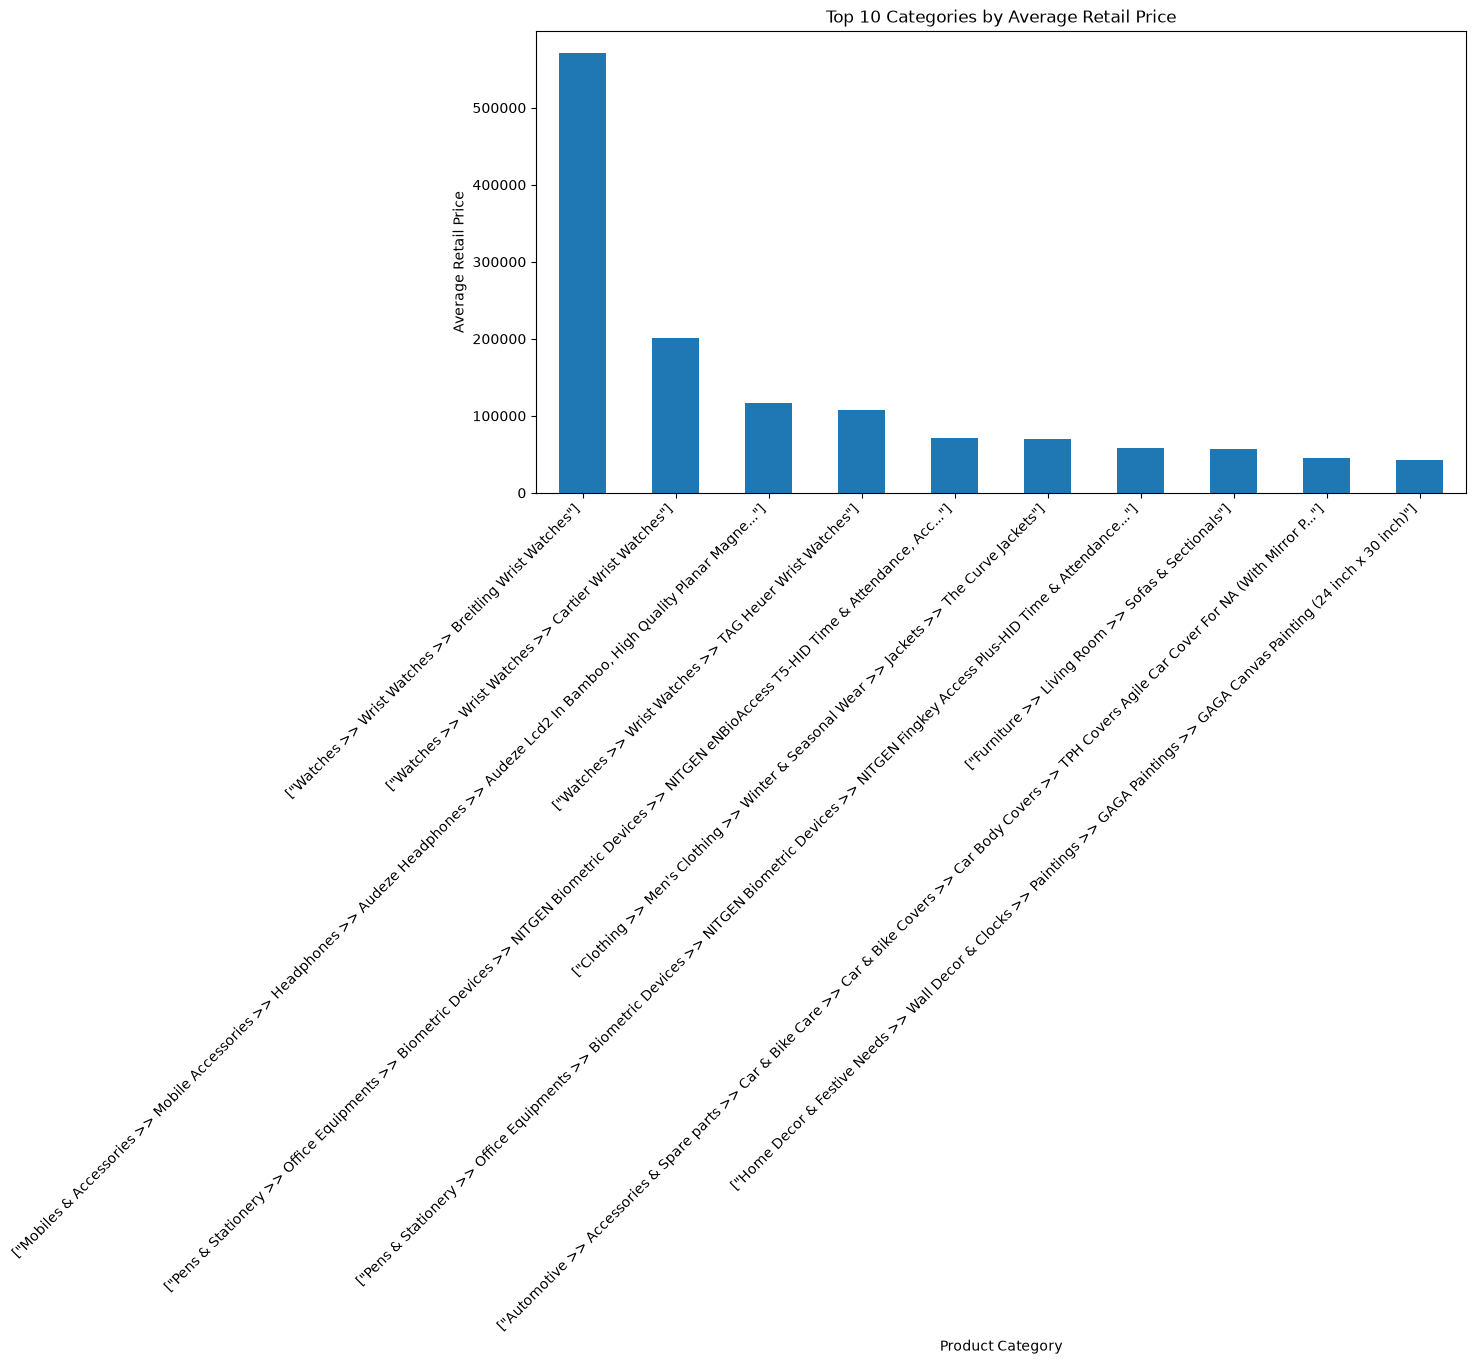

In [68]:
plt.figure(figsize=(12, 6))

category_price.plot(kind="bar")

plt.title("Top 10 Categories by Average Retail Price")
plt.xlabel("Product Category")
plt.ylabel("Average Retail Price")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

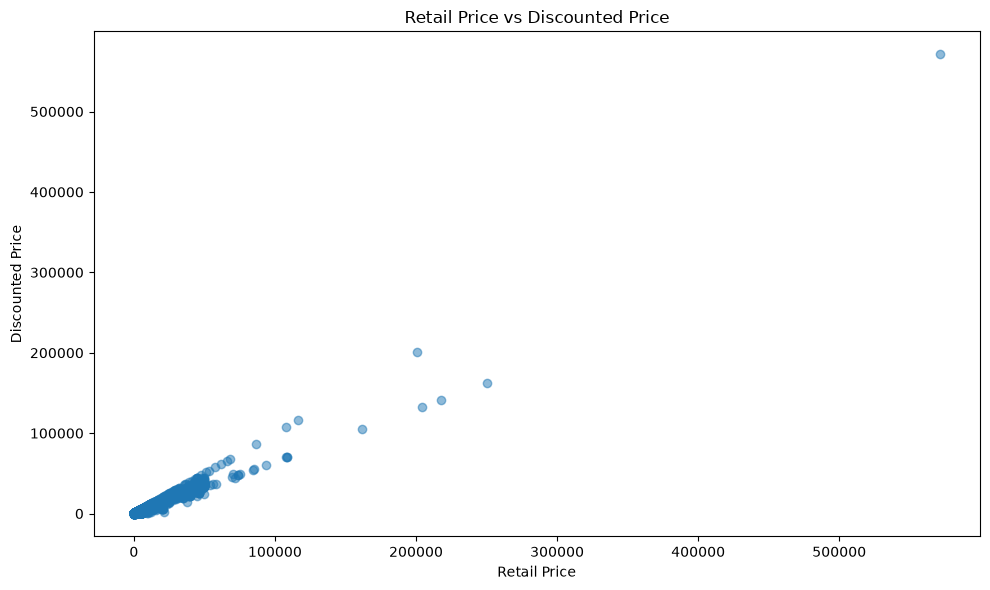

In [69]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["retail_price"],
    df["discounted_price"],
    alpha=0.5
)

plt.title("Retail Price vs Discounted Price")
plt.xlabel("Retail Price")
plt.ylabel("Discounted Price")

plt.tight_layout()
plt.show()

In [70]:
correlation = df[
    ["retail_price", "discounted_price", "discount_amount"]
].corr()

print(correlation)

                  retail_price  discounted_price  discount_amount
retail_price          1.000000          0.981180         0.788268
discounted_price      0.981180          1.000000         0.654614
discount_amount       0.788268          0.654614         1.000000


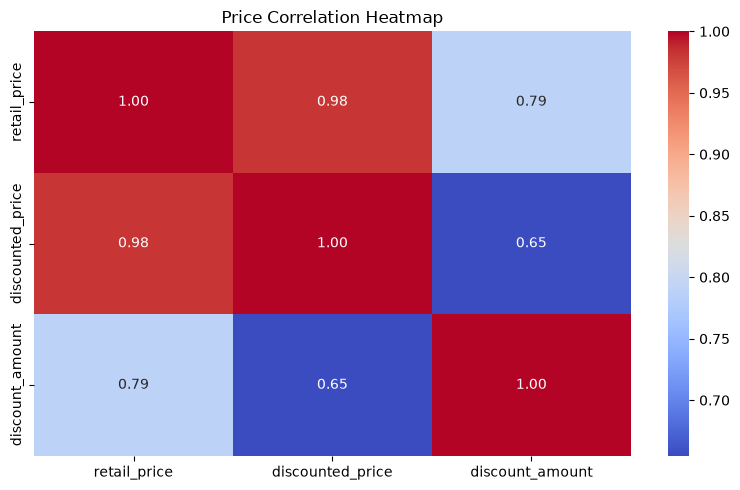

In [71]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Price Correlation Heatmap")
plt.tight_layout()
plt.show()

In [72]:
best_value = df[
    df["discount_percentage"].notna()
].nlargest(10, "discount_percentage")

best_value[
    ["product_name", "retail_price", "discounted_price", "discount_percentage"]
]

,product_name,retail_price,discounted_price,discount_percentage
17205,Rajcrafts Floral Double Quilts & Comforters White,6000.0,208.0,96.533333
7284,FashBlush Forever New Orange Bead & Chain Allo...,3999.0,189.0,95.273818
6566,FashBlush Forever Beautiful White Bead Alloy N...,3499.0,189.0,94.598457
10941,Bling Book Case for iPad 2 / 3,1816.0,99.0,94.548458
6368,FashBlush Forever New BlackBead & LongChain Al...,4999.0,279.0,94.418884
7156,Fashblush Alloy Choker,4499.0,289.0,93.576350
5535,Fash Blush Forever New Gold & White Pearl Chun...,2999.0,199.0,93.364455
6080,FashBlush Forever New BlackBead Alloy Necklace,2999.0,199.0,93.364455
16195,Mydress Mystyle Bulb Led USB Led Light,999.0,75.0,92.492492
5886,Fash Blush Forever New Red & Gold Tribal Threa...,2499.0,198.0,92.076831


In [73]:
print("Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (19922, 18)

Duplicate Rows: 0

Missing Values:
uniq_id                        0
crawl_timestamp                0
product_url                    0
product_name                   0
product_category_tree          0
pid                            0
retail_price                   0
discounted_price               0
image                          3
is_FK_Advantage_product        0
description                    2
product_rating                 0
overall_rating                 0
brand                          0
product_specifications        12
discount_amount                0
discount_percentage            0
product_rating_numeric     18083
dtype: int64

Data Types:
uniq_id                        str
crawl_timestamp                str
product_url                    str
product_name                   str
product_category_tree          str
pid                            str
retail_price               float64
discounted_price           float64
image                          str
is

In [74]:
df.to_csv("../Dataset/flipkart_cleaned_dataset.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [75]:
print("FLIPKART PRODUCT ANALYSIS - KEY INSIGHTS")
print("-" * 45)

print("\n1. Total Products:", len(df))

print("\n2. Average Retail Price:",
      round(df["retail_price"].mean(), 2))

print("\n3. Average Discounted Price:",
      round(df["discounted_price"].mean(), 2))

print("\n4. Average Discount Percentage:",
      round(df["discount_percentage"].mean(), 2), "%")

print("\n5. Most Common Brand:",
      df["brand"].mode()[0])

print("\n6. Most Common Product Category:")
print(df["product_category_tree"].mode()[0])

print("\n7. Highest Retail Price:")
print(df["retail_price"].max())

print("\n8. Highest Discount Percentage:")
print(round(df["discount_percentage"].max(), 2), "%")

FLIPKART PRODUCT ANALYSIS - KEY INSIGHTS
---------------------------------------------

1. Total Products: 19922

2. Average Retail Price: 2979.21

3. Average Discounted Price: 1973.4

4. Average Discount Percentage: 40.52 %

5. Most Common Brand: Unknown

6. Most Common Product Category:
["Jewellery >> Necklaces & Chains >> Necklaces"]

7. Highest Retail Price:
571230.0

8. Highest Discount Percentage:
96.53 %


## Conclusion

The Flipkart Product Analysis project was conducted to understand product prices, discounts, brands, categories, and ratings using Python.

The dataset was loaded and explored using Pandas and NumPy. Data cleaning techniques were applied to handle duplicate records, missing values, and data types. New features such as discount amount and discount percentage were created.

Exploratory Data Analysis (EDA) was performed to identify product categories, popular brands, price distributions, and discount patterns. Visualizations such as bar charts, histograms, scatter plots, and a correlation heatmap helped present the findings clearly.

This project improved my practical knowledge of Python, Pandas, NumPy, Matplotlib, Seaborn, data cleaning, data analysis, and data visualization.

The analysis is based on the available dataset and does not represent the complete sales performance of Flipkart.


C:\Users\uppus\AppData\Local\Temp\ipykernel_13908\3399161827.py:10: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


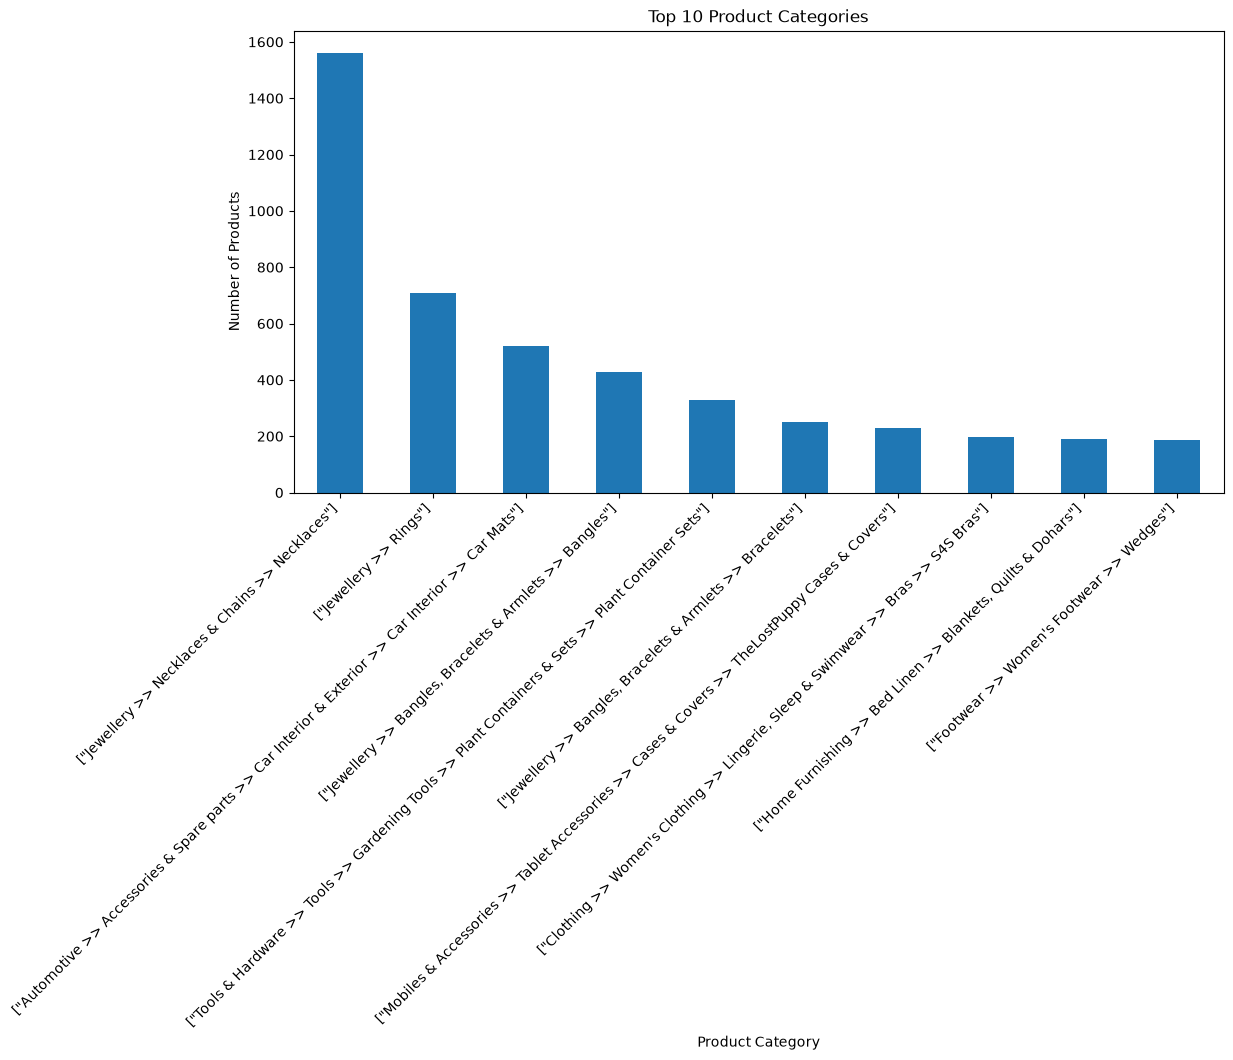

Chart saved successfully!


In [76]:
top_categories = df["product_category_tree"].value_counts().head(10)

plt.figure(figsize=(12, 6))
top_categories.plot(kind="bar")

plt.title("Top 10 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("../Visualizations/top_product_categories.png",
            dpi=300, bbox_inches="tight")

plt.show()

print("Chart saved successfully!")

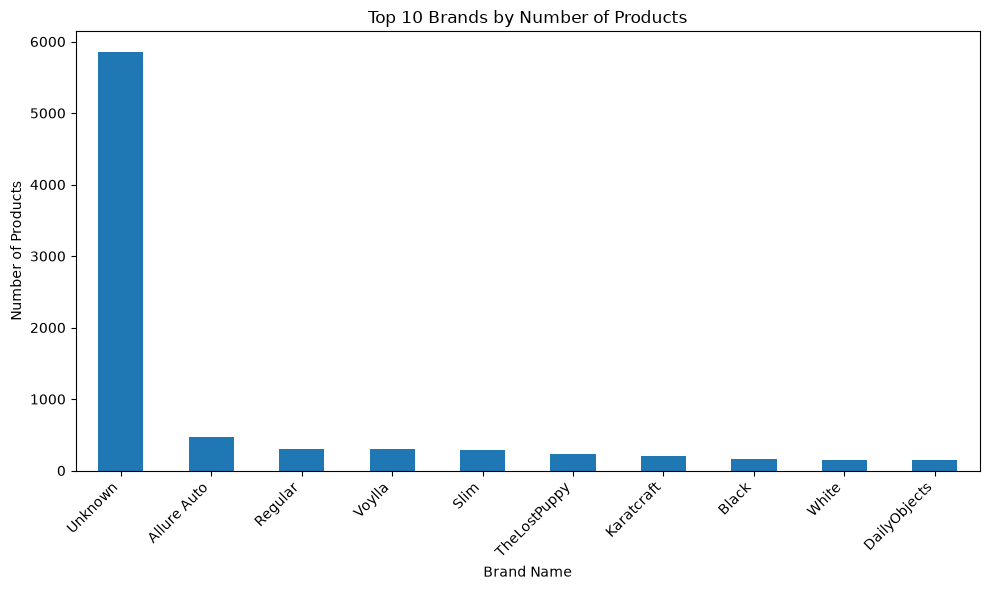

Brand chart saved successfully!


In [77]:
top_brands = df["brand"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_brands.plot(kind="bar")

plt.title("Top 10 Brands by Number of Products")
plt.xlabel("Brand Name")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("../Visualizations/top_10_brands.png",
            dpi=300, bbox_inches="tight")

plt.show()

print("Brand chart saved successfully!")

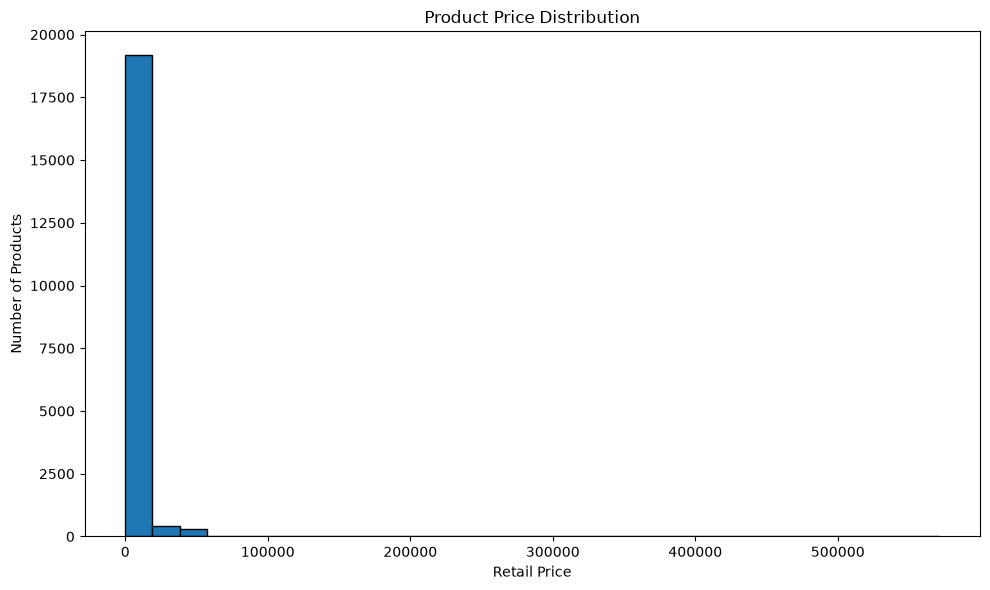

Price distribution chart saved successfully!


In [78]:
plt.figure(figsize=(10, 6))

plt.hist(df["retail_price"].dropna(), bins=30, edgecolor="black")

plt.title("Product Price Distribution")
plt.xlabel("Retail Price")
plt.ylabel("Number of Products")

plt.tight_layout()

plt.savefig(
    "../Visualizations/product_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Price distribution chart saved successfully!")

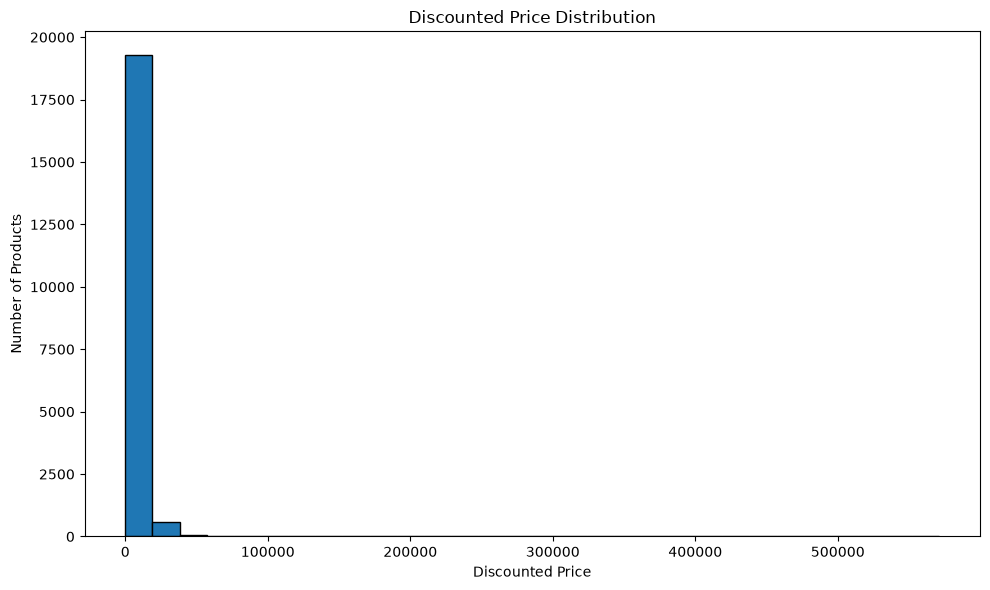

Discounted price chart saved successfully!


In [79]:
plt.figure(figsize=(10, 6))

plt.hist(df["discounted_price"].dropna(), bins=30, edgecolor="black")

plt.title("Discounted Price Distribution")
plt.xlabel("Discounted Price")
plt.ylabel("Number of Products")

plt.tight_layout()

plt.savefig(
    "../Visualizations/discounted_price_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Discounted price chart saved successfully!")

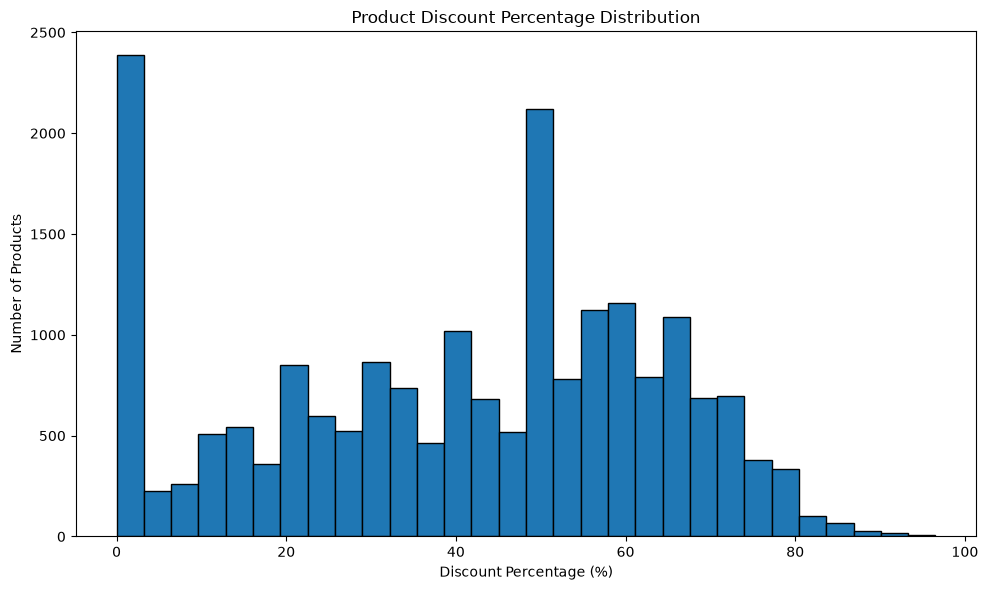

Discount percentage chart saved successfully!


In [80]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["discount_percentage"].dropna(),
    bins=30,
    edgecolor="black"
)

plt.title("Product Discount Percentage Distribution")
plt.xlabel("Discount Percentage (%)")
plt.ylabel("Number of Products")

plt.tight_layout()

plt.savefig(
    "../Visualizations/discount_percentage_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Discount percentage chart saved successfully!")

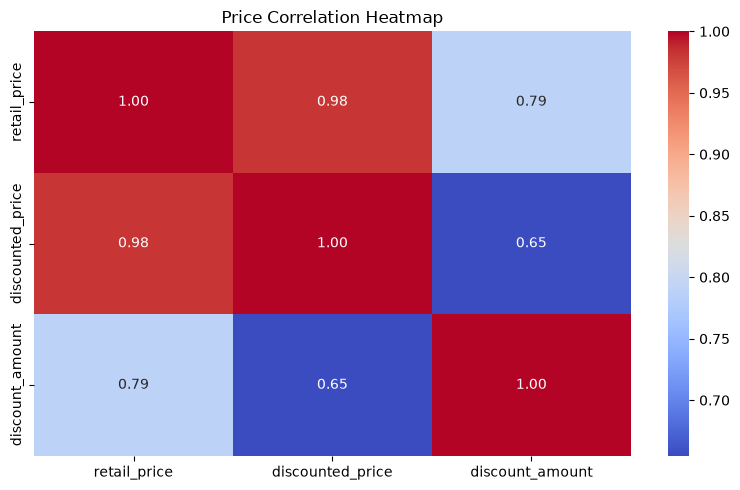

Correlation heatmap saved successfully!


In [81]:
correlation = df[
    ["retail_price", "discounted_price", "discount_amount"]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Price Correlation Heatmap")
plt.tight_layout()

plt.savefig(
    "../Visualizations/price_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully!")

In [83]:

import os

report = f"""# Flipkart Product Analysis Report

## 1. Project Overview
This project analyzes Flipkart product data to understand product
prices, discounts, brands, categories, and ratings.

## 2. Objectives
- Analyze product prices.
- Identify popular brands and categories.
- Analyze product discounts.
- Explore product ratings.
- Visualize important patterns in the dataset.

## 3. Dataset Summary
- Total products analyzed: {len(df)}
- Total columns: {df.shape[1]}
- Duplicate rows: {df.duplicated().sum()}

## 4. Key Findings
- Average retail price: {df['retail_price'].mean():.2f}
- Average discounted price: {df['discounted_price'].mean():.2f}
- Average discount percentage: {df['discount_percentage'].mean():.2f}%
- Most common brand: {df['brand'].mode().iloc[0] if not df['brand'].mode().empty else 'N/A'}
- Most common category: {df['product_category_tree'].mode().iloc[0] if not df['product_category_tree'].mode().empty else 'N/A'}
- Maximum retail price: {df['retail_price'].max():.2f}
- Maximum discount percentage: {df['discount_percentage'].max():.2f}%

## 5. Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 6. Visualizations
The project includes charts for:
- Product category distribution
- Top brands
- Retail price distribution
- Discounted price distribution
- Discount percentage distribution
- Price correlation heatmap

## 7. Conclusion
This project uses a publicly available Flipkart product dataset
to analyze pricing, discounts, brands, categories, and ratings.
The visualizations help summarize product patterns and support
better understanding of product pricing.

Note: This is dataset-based analysis, not live website scraping.
"""

os.makedirs("../Reports", exist_ok=True)

with open(
    "../Reports/Flipkart_Product_Analysis_Report.md",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print("Final project report saved successfully!")
print("Location: Reports/Flipkart_Product_Analysis_Report.md")


Final project report saved successfully!
Location: Reports/Flipkart_Product_Analysis_Report.md


In [85]:

import os

print("DATASET FILES:")
print(os.listdir("../Dataset"))

print("\nVISUALIZATION FILES:")
print(os.listdir("../Visualizations"))

print("\nREPORT FILES:")
print(os.listdir("../Reports"))

DATASET FILES:
['flipkart_cleaned_dataset.csv', 'flipkart_com-ecommerce_sample.csv']

VISUALIZATION FILES:
['discounted_price_distribution.png', 'discount_percentage_distribution.png', 'price_correlation_heatmap.png', 'product_price_distribution.png', 'top_10_brands.png', 'top_product_categories.png']

REPORT FILES:
['Flipkart_Product_Analysis_Report.md']
